# Selection and trade diagnostics

Explain the fixed Dome development comparison: which events each policy monitors, which trades differ, when gaps first appear, and why net P&L differs. This notebook uses the existing 100 ms, uncapped persistent replay. It does not fit models or open the final test.

The full interpretation is in [the diagnostic report](../docs/reports/selection_diagnostics.md). All figures and dollar tables below derive from saved attempts, not sums of training targets.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/config.py').exists())
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.reporting.workflow import profitability_run, profitability_dataset, execution_path, timestamp
from src.reporting.selection_diagnostics import (build_diagnostics, plot_diagnostics, trace_loss_case,
    seal_diagnostics, verify_diagnostics, FOCUS, REFERENCE)
from matplotlib import pyplot as plt
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
run_dir, dataset_dir = profitability_run(), profitability_dataset()
RUN_DIAGNOSTICS = False
folder = run_dir / 'selection_diagnostics'
if RUN_DIAGNOSTICS:
    folder = ROOT / 'results' / 'runs' / ('selection_diagnostics_' + timestamp())
    build_diagnostics(run_dir, dataset_dir, folder)
    for figure in plot_diagnostics(folder).values():
        plt.close(figure)
    trace_loss_case(folder, run_dir)
    seal_diagnostics(folder)
manifest = verify_diagnostics(folder, run_dir, dataset_dir)
summary = pd.read_csv(folder / 'policy_summary.csv').set_index('model')
selected = pd.read_parquet(folder / 'selected_windows.parquet')
attempts = pd.read_parquet(folder / 'annotated_attempts.parquet')
paired = pd.read_parquet(folder / 'attempt_comparisons.parquet')
print({k: manifest[k] for k in ['evaluation_start', 'evaluation_last_scan', 'hours',
    'competitive_hours', 'eligible_events', 'eligible_event_windows', 'final_lockbox_opened']})
print('Verified diagnostic folder:', folder.relative_to(ROOT))

{'evaluation_start': '2025-11-01 00:00:00+00:00', 'evaluation_last_scan': '2026-01-07 23:00:00+00:00', 'hours': 1632, 'competitive_hours': 1437, 'eligible_events': 44, 'eligible_event_windows': 20951, 'final_lockbox_opened': False}
Verified diagnostic folder: results\profitability\selection_diagnostics


## Net P&L and opportunity capture

Representative learned policies are the highest observed development performers in their main families, chosen descriptively after comparing variants. The full table covers all main variants. Recall counts known hours with at least one profitable attempt, not net-profitable hours. An hour can contain profitable attempts and still lose money overall.

,known_pnl_usd,completed_pnl_usd,partial_pnl_usd,attempts,losing_attempts,unknown_attempts,positive_hour_recall,future_positive_hour_recall
model,,,,,,,,
quoted_gap_rule,"6,045.2515","6,328.7206",-283.4690,491,17,0,0.9176,0.8719
combined_random_forest,"5,942.7078","6,357.4540",-414.7462,513,18,0,0.9574,0.9339
combined_reg_ensemble,"5,842.3872","6,255.0526",-412.6654,458,17,0,0.8777,0.8347
combined_two_stage_random_forest,"5,903.5544","6,318.3006",-414.7462,496,18,0,0.9069,0.8595
monitor_all,"5,951.6045","6,366.3507",-414.7462,521,18,0,1.0000,1.0000


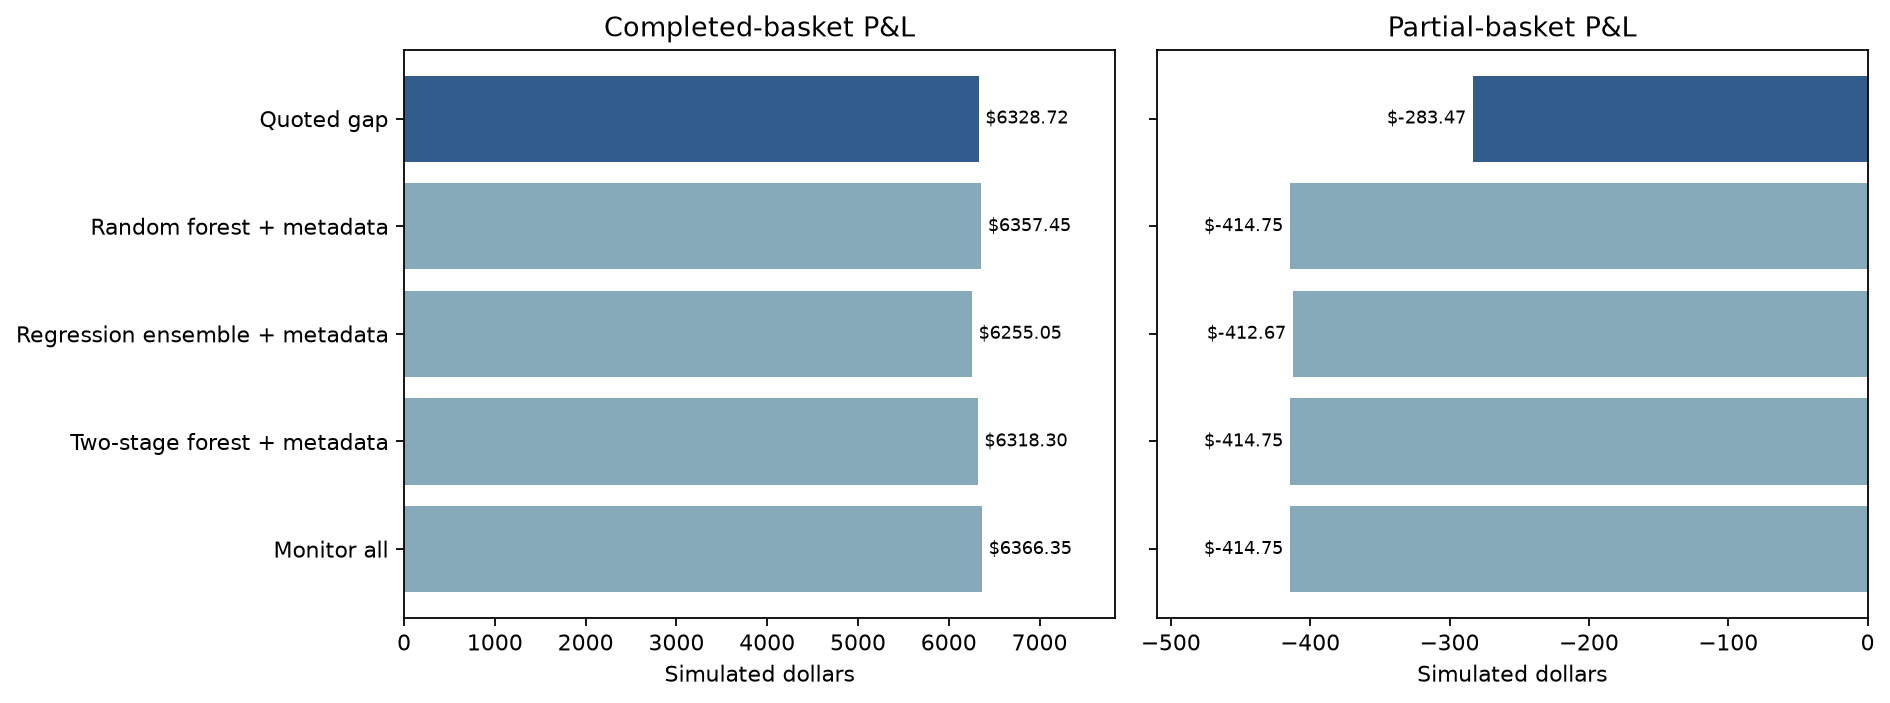

,known_pnl_usd,net_difference_usd,common_fraction,competitive_common_fraction,selected_unknown
model,,,,,
quoted_gap_rule,"6,045.2515",0.0000,1.0000,1.0000,1518
monitor_all,"5,951.6045",-93.6470,1.0000,1.0000,3994
combined_random_forest,"5,942.7078",-102.5438,0.8866,0.8732,1409
random_forest,"5,942.4238",-102.8278,0.8952,0.8828,1297
rank_ensemble,"5,942.0156",-103.2360,0.8464,0.8283,1165
combined_rank_ensemble,"5,939.9475",-105.3040,0.8392,0.8202,1336
combined_boosted_trees,"5,929.1010",-116.1506,0.8569,0.8399,1403
combined_logistic,"5,925.4577",-119.7939,0.8038,0.7807,1086
combined_two_stage_random_forest,"5,903.5544",-141.6971,0.8332,0.8135,1496


In [2]:
display(summary.loc[FOCUS, ['known_pnl_usd', 'completed_pnl_usd', 'partial_pnl_usd', 'attempts',
    'losing_attempts', 'unknown_attempts', 'positive_hour_recall', 'future_positive_hour_recall']])
display(Image(filename=str(folder / 'profit_and_losses.png')))
display(summary[['known_pnl_usd', 'net_difference_usd', 'common_fraction', 'competitive_common_fraction',
    'selected_unknown']].sort_values('known_pnl_usd', ascending=False))

## Monitoring overlap and exact P&L attribution

Overlap is measured against quoted-gap's selected event-hours. The competitive version excludes hours with five or fewer candidates. Shared selections can produce different attempts because earlier monitoring decisions change the persistent reservation ledger. The category differences below sum exactly to each model's net-P&L difference.

,model,selection_group,windows,model_net_usd,rule_net_usd,difference_usd
36,combined_random_forest,both,7123,"6,028.0357","6,039.4091",-11.3733
37,combined_random_forest,model_only,911,-85.3280,0.0000,-85.3280
38,combined_random_forest,rule_only,911,0.0000,5.8425,-5.8425
72,combined_reg_ensemble,both,5820,"5,932.5319","5,940.4879",-7.9559
73,combined_reg_ensemble,model_only,2214,-90.1447,0.0000,-90.1447
74,combined_reg_ensemble,rule_only,2214,0.0000,104.7637,-104.7637
132,combined_two_stage_random_forest,both,6694,"5,991.4650","5,987.8805",3.5845
133,combined_two_stage_random_forest,model_only,1340,-87.9106,0.0000,-87.9106
134,combined_two_stage_random_forest,rule_only,1340,0.0000,57.3710,-57.3710


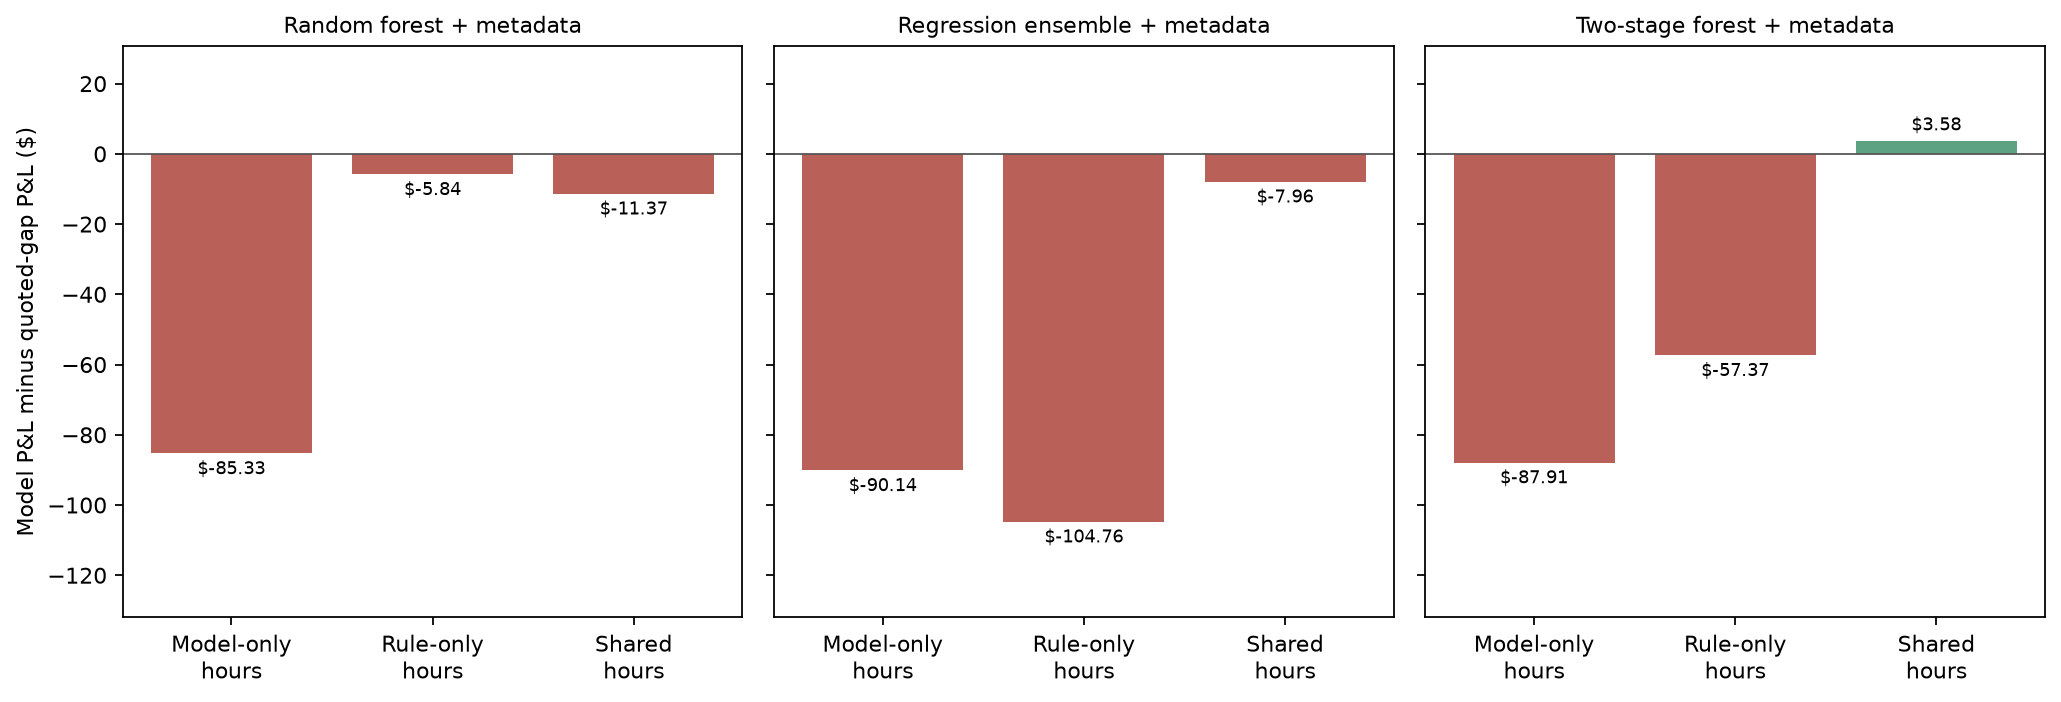

,attempts,forest_pnl,rule_pnl,difference,unknown_comparisons
presence,,,,,
both,477,"6,027.8528","6,027.8528",0.0000,0
model_only,36,-85.1450,0.0000,-85.1450,0
rule_only,14,0.0000,17.3988,-17.3988,0


,event_slug,decision_time,start_time,presence,status_model,net_usd_model,net_usd_rule,difference_usd
1749,fed-decision-in-december,2025-11-19 17:00:00+00:00,2025-11-19 17:24:06.666000+00:00,model_only,partial_unwound,-131.2772,0.0000,-131.2772
2005,honduras-presidential-election,2025-11-27 14:00:00+00:00,2025-11-27 14:00:00+00:00,rule_only,NaN,0.0000,7.0965,-7.0965
1874,fed-decision-in-january,2025-11-13 15:00:00+00:00,2025-11-13 15:15:11.582000+00:00,rule_only,NaN,0.0000,4.3007,-4.3007
2007,honduras-presidential-election,2025-11-27 18:00:00+00:00,2025-11-27 18:36:48.930000+00:00,rule_only,NaN,0.0000,3.1240,-3.1240
1986,honduras-presidential-election,2025-11-11 10:00:00+00:00,2025-11-11 10:34:20.783000+00:00,rule_only,NaN,0.0000,1.3318,-1.3318
1904,fed-decision-in-january,2025-11-23 08:00:00+00:00,2025-11-23 08:00:00+00:00,rule_only,NaN,0.0000,1.0720,-1.0720
2019,largest-company-end-of-november,2025-11-10 01:00:00+00:00,2025-11-10 01:58:12.702000+00:00,rule_only,NaN,0.0000,0.1260,-0.1260
2110,which-party-holds-the-most-seats-after-argenti...,2025-11-23 07:00:00+00:00,2025-11-23 07:00:00+00:00,rule_only,NaN,0.0000,0.0800,-0.0800
2012,honduras-presidential-election,2025-11-29 05:00:00+00:00,2025-11-29 05:00:00+00:00,rule_only,NaN,0.0000,0.0800,-0.0800
1870,fed-decision-in-january,2025-11-03 20:00:00+00:00,2025-11-03 20:00:00+00:00,rule_only,NaN,0.0000,0.0788,-0.0788


In [3]:
attribution = pd.read_csv(folder / 'selection_attribution.csv')
display(attribution.loc[attribution.model.isin(FOCUS[1:4]) & attribution.fold.eq('all'),
    ['model', 'selection_group', 'windows', 'model_net_usd', 'rule_net_usd', 'difference_usd']])
display(Image(filename=str(folder / 'selection_attribution.png')))
forest = paired.loc[paired.model.eq('combined_random_forest')]
display(forest.groupby('presence').agg(attempts=('start_time', 'size'),
    forest_pnl=('net_usd_model', 'sum'), rule_pnl=('net_usd_rule', 'sum'),
    difference=('difference_usd', 'sum'), unknown_comparisons=('unknown_comparison', 'sum')))
display(forest.loc[forest.difference_usd.abs().gt(1e-8), ['event_slug', 'decision_time', 'start_time',
    'presence', 'status_model', 'net_usd_model', 'net_usd_rule', 'difference_usd']]
    .sort_values('difference_usd').head(12))

## Existing gaps versus new observed onsets

A gap already open at the hourly scan is separated from a gap with an observed onset strictly later. A later first observation with no preceding observed state is kept separate. A new gap in one basket does not imply the entire event had no other positive gap at screening, so the stricter nonpositive-score subset is also shown.

These are recorded onsets under the existing capture assumptions. Attempt counts are not counts of independent economic opportunities; an episode may continue across hourly boundaries.

attempts  \
model                            onset                                           
combined_random_forest           first_seen_after_scan_onset_unknown         1   
                                 new_observed_after_scan                   436   
                                 visible_at_scan                            76   
combined_reg_ensemble            first_seen_after_scan_onset_unknown         1   
                                 new_observed_after_scan                   381   
                                 visible_at_scan                            76   
combined_two_stage_random_forest first_seen_after_scan_onset_unknown         1   
                                 new_observed_after_scan                   414   
                                 visible_at_scan                            81   
monitor_all                      first_seen_after_scan_onset_unknown         1   
                                 new_observed_after_scan                   450   
                                 visible_at_scan                            70   
quoted_gap_rule                  first_seen_after_scan_onset_unknown         1   
                                 new_observed_after_scan                   412   
                                 visible_at_scan                            78   

                                                                      known_pnl_usd  \
model                            onset                                                
combined_random_forest           first_seen_after_scan_onset_unknown         1.3690   
                                 new_observed_after_scan                 3,755.0260   
                                 visible_at_scan                         2,186.3128   
combined_reg_ensemble            first_seen_after_scan_onset_unknown         1.3690   
                                 new_observed_after_scan                 3,655.2648   
                                 visible_at_scan                         2,185.7534   
combined_two_stage_random_forest first_seen_after_scan_onset_unknown         1.3690   
                                 new_observed_after_scan                 3,700.9149   
                                 visible_at_scan                         2,201.2705   
monitor_all                      first_seen_after_scan_onset_unknown         1.3690   
                                 new_observed_after_scan                 3,765.0395   
                                 visible_at_scan                         2,185.1960   
quoted_gap_rule                  first_seen_after_scan_onset_unknown         1.3690   
                                 new_observed_after_scan                 3,849.3205   
                                 visible_at_scan                         2,194.5621   

                                                                      unknown_attempts  
model                            onset                                                  
combined_random_forest           first_seen_after_scan_onset_unknown                 0  
                                 new_observed_after_scan                             0  
                                 visible_at_scan                                     0  
combined_reg_ensemble            first_seen_after_scan_onset_unknown                 0  
                                 new_observed_after_scan                             0  
                                 visible_at_scan                                     0  
combined_two_stage_random_forest first_seen_after_scan_onset_unknown                 0  
                                 new_observed_after_scan                             0  
                                 visible_at_scan                                     0  
monitor_all                      first_seen_after_scan_onset_unknown                 0  
                                 new_observed_after_scan                             0  
                                 visib

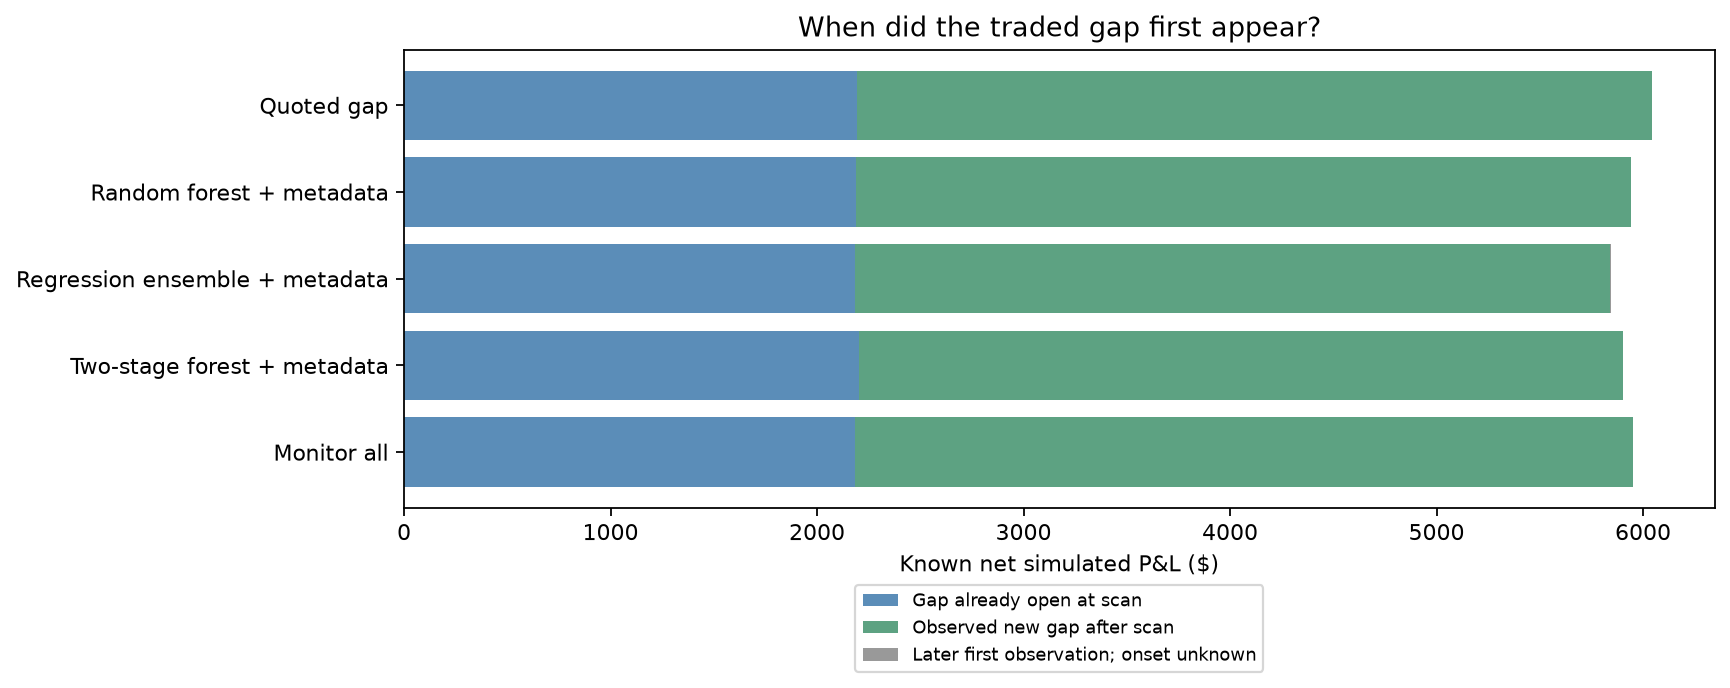

,attempts,known_pnl_usd
model,,
combined_random_forest,378,"2,870.5001"
combined_reg_ensemble,325,"2,771.0499"
combined_two_stage_random_forest,357,"2,816.4850"
monitor_all,392,"2,880.5136"
quoted_gap_rule,354,"2,964.7946"


,population,scan_state,windows,known_windows,positive_hours,observed_future_positive_hours,qualified_entry_windows
0,all_candidates,nonpositive_quote,7984,6655,223,223,0
1,all_candidates,positive_quote,187,158,153,19,178
2,all_candidates,quote_unavailable,12780,10144,0,0,0
3,combined_random_forest,nonpositive_quote,6425,5217,207,207,0
4,combined_random_forest,positive_quote,187,158,153,19,178
5,combined_random_forest,quote_unavailable,1422,1250,0,0,0
6,combined_reg_ensemble,nonpositive_quote,5170,4271,184,184,0
7,combined_reg_ensemble,positive_quote,171,151,146,18,165
8,combined_reg_ensemble,quote_unavailable,2693,2452,0,0,0
9,combined_two_stage_random_forest,nonpositive_quote,6259,5056,189,189,0


In [4]:
onsets = pd.read_csv(folder / 'onset_breakdown.csv')
display(onsets.loc[onsets.model.isin(FOCUS)].groupby(['model', 'onset']).agg(
    attempts=('attempts', 'sum'), known_pnl_usd=('known_pnl_usd', 'sum'),
    unknown_attempts=('unknown_attempts', 'sum')))
display(Image(filename=str(folder / 'opportunity_onsets.png')))
display(onsets.loc[onsets.model.isin(FOCUS) & onsets.scan_state.eq('nonpositive_quote') &
    onsets.onset.eq('new_observed_after_scan')].groupby('model').agg(
    attempts=('attempts', 'sum'), known_pnl_usd=('known_pnl_usd', 'sum')))
display(pd.read_csv(folder / 'scan_states.csv'))

## Raw-book reconstruction of the largest forest-only loss

This case is selected retrospectively by its contribution to the P&L difference. It does not establish a predictive failure-avoidance rule. The trace keeps the submitted quantity and price limits fixed when inspecting arrival books. The `scan` rows are retrospective comparisons using the later order's size and limits; they were not inputs to the earlier ranking. The notebook displays submit, arrival and unwind rows below.

In [5]:
case = json.loads((folder / 'loss_case.json').read_text())
display(pd.Series(case, name='Case study'))
ranks = pd.read_csv(folder / 'loss_case_rankings.csv')
display(ranks.loc[ranks['rank'].le(6), ['model', 'event_slug', 'score', 'rank', 'selected']])
books = pd.read_csv(folder / 'loss_case_books.csv', dtype={'token_id': str})
display(books.loc[books.stage.ne('scan'), ['stage', 'leg', 'question', 'snapshot_time',
    'age_seconds', 'quantity', 'fixed_buy_limit', 'ask_depth_within_limit',
    'buy_cost_within_limit_usd', 'unwind_bid_proceeds_usd', 'filled']])
display(summary.loc[FOCUS[1:4], ['net_difference_usd', 'largest_trade_difference_usd',
    'difference_excluding_largest_trade_usd']])

event_slug                                        fed-decision-in-december
decision_time                                    2025-11-19 17:00:00+00:00
start_time                                2025-11-19 17:24:06.666000+00:00
arrival_time                              2025-11-19 17:24:06.766000+00:00
unwind_time                               2025-11-19 17:24:07.766000+00:00
quantity                                                              3171
n_members                                                                4
n_filled_legs                                                            3
quoted_gross_usd                                                    4.1910
entry_cost_usd                                                  1,803.2790
pnl_usd                                                          -131.2772
model                                               combined_random_forest
reconstructed_pnl_usd                                            -131.2772
final_lockbox_opened     

,model,event_slug,score,rank,selected
0,quoted_gap_rule,fed-decision-in-january,0.0280,1,True
1,quoted_gap_rule,what-price-will-bitcoin-hit-in-november-2025,-0.0050,2,True
2,quoted_gap_rule,what-price-will-ethereum-hit-in-november-2025,-0.0050,3,True
3,quoted_gap_rule,monad-market-cap-fdv-one-day-after-launch,-0.0350,4,True
4,quoted_gap_rule,honduras-presidential-election,-0.0850,5,True
5,quoted_gap_rule,fed-decision-in-december,-0.0900,6,False
16,combined_random_forest,fed-decision-in-january,0.7353,1,True
17,combined_random_forest,fed-decision-in-december,0.6077,2,True
18,combined_random_forest,monad-market-cap-fdv-one-day-after-launch,0.5618,3,True
19,combined_random_forest,what-price-will-ethereum-hit-in-november-2025,0.3783,4,True


,stage,leg,question,snapshot_time,age_seconds,quantity,fixed_buy_limit,ask_depth_within_limit,buy_cost_within_limit_usd,unwind_bid_proceeds_usd,filled
4,submit,0,Fed decreases interest rates by 50+ bps after ...,2025-11-19 17:23:46.183000+00:00,20.4830,3171,0.0230,"22,640.8600",72.9330,69.7620,True
5,submit,1,Fed decreases interest rates by 25 bps after D...,2025-11-19 17:24:06.666000+00:00,0.0000,3171,0.4300,"3,171.4900","1,363.5300","1,327.2147",False
6,submit,2,No change in Fed interest rates after December...,2025-11-19 17:24:04.897000+00:00,1.7690,3171,0.5400,"33,336.9300","1,711.3200","1,536.7648",True
7,submit,3,Fed increases interest rates by 25+ bps after ...,2025-11-19 17:23:20.041000+00:00,46.6250,3171,0.0060,"2,596,374.6600",19.0260,15.8550,True
8,arrival,0,Fed decreases interest rates by 50+ bps after ...,2025-11-19 17:23:46.183000+00:00,20.5830,3171,0.0230,"22,640.8600",72.9330,69.7620,True
9,arrival,1,Fed decreases interest rates by 25 bps after D...,2025-11-19 17:24:06.727000+00:00,0.0390,3171,0.4300,"1,171.4900",NaN,"1,327.2147",False
10,arrival,2,No change in Fed interest rates after December...,2025-11-19 17:24:04.897000+00:00,1.8690,3171,0.5400,"33,336.9300","1,711.3200","1,536.7648",True
11,arrival,3,Fed increases interest rates by 25+ bps after ...,2025-11-19 17:23:20.041000+00:00,46.7250,3171,0.0060,"2,596,374.6600",19.0260,15.8550,True
12,unwind,0,Fed decreases interest rates by 50+ bps after ...,2025-11-19 17:23:46.183000+00:00,21.5830,3171,0.0230,"22,640.8600",72.9330,69.7620,True
13,unwind,1,Fed decreases interest rates by 25 bps after D...,2025-11-19 17:24:07.166000+00:00,0.6000,3171,0.4300,"1,163.4900",NaN,"1,327.2147",False


,net_difference_usd,largest_trade_difference_usd,difference_excluding_largest_trade_usd
model,,,
combined_random_forest,-102.5438,-131.2772,28.7334
combined_reg_ensemble,-202.8643,-131.2772,-71.5871
combined_two_stage_random_forest,-141.6971,-131.2772,-10.4199


The last column is only an accounting sensitivity: remove the largest differential trade while holding every other attempt fixed. It is not a replayed policy and cannot be interpreted as achievable performance. The actual loss remains in the primary results.

## Fold stability and event concentration

The event exclusion below is the existing reranked sensitivity: remove December Fed from the pool, reallocate slots, and keep fitted models fixed. It differs from simply subtracting that event's P&L.

In [6]:
folds = pd.read_csv(folder / 'fold_summary.csv')
display(folds.loc[folds.model.isin(FOCUS)].pivot(index='fold', columns='model', values='known_pnl_usd'))
events = pd.read_csv(folder / 'event_contributions.csv')
display(events.loc[events.model.isin(FOCUS)].pivot(index='event_slug', columns='model',
    values='known_pnl_usd').fillna(0))
existing = pd.read_csv(execution_path(run_dir) / 'summary.csv')
display(existing.loc[existing.scope.eq('exclude_december_fed') & existing.fold.eq('all') &
    existing.model.isin(FOCUS), ['model', 'known_pnl_usd', 'partial_pnl_usd', 'unknown_attempts']])

model,combined_random_forest,combined_reg_ensemble,combined_two_stage_random_forest,monitor_all,quoted_gap_rule
fold,,,,,
dec_late,331.9287,331.9287,331.9287,331.9287,331.9287
nov_early,"4,500.1344","4,437.8957","4,482.4788","4,508.5482","4,622.7116"
nov_late,"1,110.6448","1,072.5628","1,089.1469","1,111.1277","1,090.6112"


model,combined_random_forest,combined_reg_ensemble,combined_two_stage_random_forest,monitor_all,quoted_gap_rule
event_slug,,,,,
avatar-fire-and-ash-opening-weekend-box-office,30.9882,33.0249,30.9882,30.9882,30.9882
boxing-jake-paul-vs-anthony-joshua-third-option-included,-57.9743,-57.9743,-57.9743,-57.9743,-57.9743
fed-decision-in-december,"5,222.4543","5,165.8143","5,195.1343","5,222.4543","5,332.9505"
fed-decision-in-january,530.2533,526.3727,516.6698,537.2113,532.7923
gensyn-public-sale-total-commitments,4.3450,2.3450,4.3450,4.3450,4.3450
honduras-presidential-election,104.7382,102.6978,111.1181,106.6500,98.1073
largest-company-end-of-november,5.6658,5.6658,5.6658,5.6658,4.9951
monad-market-cap-fdv-one-day-after-launch,0.9205,0.5285,0.9205,0.9475,0.9475
what-price-will-bitcoin-hit-in-november-2025,36.4240,11.4224,34.2630,36.4240,36.4240


,model,known_pnl_usd,partial_pnl_usd,unknown_attempts
252,combined_random_forest,726.8060,-130.8976,0
264,combined_reg_ensemble,682.0555,-128.8168,0
284,combined_two_stage_random_forest,717.9685,-130.8976,0
328,quoted_gap_rule,726.5680,-130.8976,0
476,monitor_all,729.1503,-130.8976,0


## Coverage and quote-age qualifications

An attempted trade can have an observed outcome even when the rest of its event-hour is not fully covered. Such trade P&L is part of the known subtotal; the incomplete hour remains unusable as a complete training target. Unknown labels are never removed before ranking.

Older unchanged quotes can be carried forward under the complete-capture assumption. Their age alone neither establishes staleness nor validates 100 ms execution. No new quote-age threshold is introduced by this analysis.

In [7]:
display(attempts.loc[attempts.model.isin(FOCUS)].groupby(['model', 'label_known']).agg(
    attempts=('net_usd', 'size'), known_pnl_usd=('net_usd', 'sum'),
    unknown_attempts=('unknown_pnl', 'sum')))
display(attempts.loc[attempts.model.isin(FOCUS)].groupby(['model', 'onset']).agg(
    median_oldest_leg_age_s=('confirmation_max_age_s', 'median'),
    maximum_oldest_leg_age_s=('confirmation_max_age_s', 'max')))
assert not manifest['final_lockbox_opened']
assert not manifest['models_retrained']
assert not manifest['execution_changed']

attempts  known_pnl_usd  \
model                            label_known                            
combined_random_forest           False             101       318.3478   
                                 True              412     5,624.3600   
combined_reg_ensemble            False              75       278.5635   
                                 True              383     5,563.8237   
combined_two_stage_random_forest False              98       315.8638   
                                 True              398     5,587.6906   
monitor_all                      False             101       318.3478   
                                 True              420     5,633.2567   
quoted_gap_rule                  False             101       318.3478   
                                 True              390     5,726.9037   

                                              unknown_attempts  
model                            label_known                    
combined_random_forest           False                       0  
                                 True                        0  
combined_reg_ensemble            False                       0  
                                 True                        0  
combined_two_stage_random_forest False                       0  
                                 True                        0  
monitor_all                      False                       0  
                                 True                        0  
quoted_gap_rule                  False                       0  
                                 True                        0

median_oldest_leg_age_s  \
model                            onset                                                          
combined_random_forest           first_seen_after_scan_onset_unknown                   7.6690   
                                 new_observed_after_scan                             162.4725   
                                 visible_at_scan                                     641.2300   
combined_reg_ensemble            first_seen_after_scan_onset_unknown                   7.6690   
                                 new_observed_after_scan                             143.1300   
                                 visible_at_scan                                     663.9695   
combined_two_stage_random_forest first_seen_after_scan_onset_unknown                   7.6690   
                                 new_observed_after_scan                             156.1540   
                                 visible_at_scan                                     815.0910   
monitor_all                      first_seen_after_scan_onset_unknown                   7.6690   
                                 new_observed_after_scan                             173.3435   
                                 visible_at_scan                                     629.6060   
quoted_gap_rule                  first_seen_after_scan_onset_unknown                   7.6690   
                                 new_observed_after_scan                             173.3435   
                                 visible_at_scan                                     671.4735   

                                                                      maximum_oldest_leg_age_s  
model                            onset                                                          
combined_random_forest           first_seen_after_scan_onset_unknown                    7.6690  
                                 new_observed_after_scan                           40,457.5900  
                                 visible_at_scan                                   28,324.4170  
combined_reg_ensemble            first_seen_after_scan_onset_unknown                    7.6690  
                                 new_observed_after_scan                           40,457.5900  
                                 visible_at_scan                                   28,324.4170  
combined_two_stage_random_forest first_seen_after_scan_onset_unknown                    7.6690  
                                 new_observed_after_scan                           25,689.3340  
                                 visible_at_scan                                   34,101.4120  
monitor_all                      first_seen_after_scan_onset_unknown                    7.6690  
                                 new_observed_after_scan                           78,562.3290  
                                 visible_at_scan                                    7,636.3530  
quoted_gap_rule                  first_seen_after_scan_onset_unknown                    7.6690  
                                 new_observed_after_scan                           78,562.3290  
                                 visible_at_scan                                   28,324.4170

## Monitoring budget sensitivity

The primary top-five replay remains unchanged. Top three is an additional persistent replay using exactly the same predictions, execution policy and coverage treatment. The comparison distinguishes all eligible candidates from candidates with a calculable quoted score; the latter is a diagnostic, not a new eligibility filter.

Set `RUN_BUDGET_REPLAY = True` only when the separate top-three replay has not yet been generated. A completed replay is preserved. Event-hour slot fractions do not measure processing savings: screening overhead and update counts must be accounted for separately.

In [8]:
from src.reporting.monitoring_budget import budget_comparison
from src.simulator.profitability import replay_profitability
RUN_BUDGET_REPLAY = False
budget_folder = run_dir / 'budget_sensitivity' / 'top3'
if RUN_BUDGET_REPLAY and not (budget_folder / 'run.json').exists():
    if budget_folder.exists():
        raise RuntimeError('An incomplete top-three replay exists; inspect it before choosing a fresh output folder.')
    replay_profitability(budget_folder, dataset_dir, run_dir, top_n=3)
budgets, competition = budget_comparison(run_dir, dataset_dir)
display(competition)
display(budgets.loc[budgets.scope.eq('all_events') & budgets.model.isin(FOCUS),
    ['budget', 'model', 'known_pnl_usd', 'completed_profit_usd', 'partial_pnl_usd',
     'attempts', 'unknown_attempts', 'recall', 'future_recall']].sort_values(['model', 'budget']))
display(budgets.loc[budgets.scope.eq('exclude_december_fed') & budgets.model.isin(FOCUS),
    ['budget', 'model', 'known_pnl_usd', 'partial_pnl_usd']].sort_values(['model', 'budget']))

,budget,hours,all_events_fit_hours,all_quoted_events_fit_hours,competitive_hours,quoted_competitive_hours,selected_event_windows,available_event_windows
0,3,1632,8,464,1624,1168,4896,20951
1,5,1632,195,910,1437,722,8034,20951


,budget,model,known_pnl_usd,completed_profit_usd,partial_pnl_usd,attempts,unknown_attempts,recall,future_recall
3,3,combined_random_forest,"5,910.4299","6,324.4122",-413.9822,448,0,0.8723,0.8058
123,5,combined_random_forest,"5,942.7078","6,357.4540",-414.7462,513,0,0.9574,0.9339
6,3,combined_reg_ensemble,"4,488.0721","4,756.6081",-268.5360,393,0,0.7473,0.6446
126,5,combined_reg_ensemble,"5,842.3872","6,255.0526",-412.6654,458,0,0.8777,0.8347
11,3,combined_two_stage_random_forest,"5,838.8879","6,250.2194",-411.3314,456,0,0.8032,0.7273
131,5,combined_two_stage_random_forest,"5,903.5544","6,318.3006",-414.7462,496,0,0.9069,0.8595
59,3,monitor_all,"5,951.6045","6,366.3507",-414.7462,521,0,NaN,NaN
179,5,monitor_all,"5,951.6045","6,366.3507",-414.7462,521,0,NaN,NaN
22,3,quoted_gap_rule,"4,379.9587","4,498.1226",-118.1639,376,0,0.7128,0.5537
142,5,quoted_gap_rule,"6,045.2515","6,328.7206",-283.4690,491,0,0.9176,0.8719


,budget,model,known_pnl_usd,partial_pnl_usd
63,3,combined_random_forest,655.8686,-130.6336
183,5,combined_random_forest,726.8060,-130.8976
66,3,combined_reg_ensemble,654.9905,-128.3168
186,5,combined_reg_ensemble,682.0555,-128.8168
71,3,combined_two_stage_random_forest,682.7038,-128.0528
191,5,combined_two_stage_random_forest,717.9685,-130.8976
119,3,monitor_all,729.1503,-130.8976
239,5,monitor_all,729.1503,-130.8976
82,3,quoted_gap_rule,729.5014,-118.1639
202,5,quoted_gap_rule,726.5680,-130.8976


## Interpretation

The forest captures more known hours containing newly emerging profitable attempts, but its extra partial-fill loss reverses the net-P&L ordering. Quoted-gap's aggregate lead is concentrated in one event and one additional losing attempt. Both methods also earn substantial P&L from events without positive quoted margins at screening.

The evidence supports studying incremental predictive value beyond the quoted margin while retaining execution losses. It does not support deleting the disputed trade, declaring a universally superior model, or opening the final test during development. See the accompanying report for the complete interpretation and limitations.